In [1]:
from typing import Literal
import pandas as pd
import os


import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [10]:
bsdr = "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/"
dirs = os.listdir("%s/controlled_extrapolation" % bsdr)

In [11]:
ix = -1
all_sub_dfs = []
for dr in dirs:
#ix+=1
#for _ in range(1):
    all_dfs = []
    #dr = dirs[ix]
    full_dr = os.path.join(bsdr, "controlled_extrapolation", dr)
    for sdr in os.listdir(full_dr):
        sub_path = os.path.join(full_dr, sdr)
        for fname in os.listdir(sub_path):
            df_path = os.path.join(sub_path, fname)
            df = pd.read_csv(df_path)


            if sdr == "linreg":
                df["model_name"] = "linreg"

            if sdr == "one_hot":
                df["model_name"] = "one_hot"

            #print(df.columns)
            if "clf_type" not in df.columns:
                if sdr == "linreg":
                    df["clf_type"] = "linreg"
                else:
                    df["clf_type"] = "mlp"
            
            if "dataset" not in df.columns:
                df["dataset"] = dr.split("_")[0]


            all_dfs.append(df)
    
    ds_df = pd.concat(all_dfs, axis=0, join="outer", ignore_index=True)
    all_sub_dfs.append(ds_df)


In [12]:
bsdr = "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/"
dirs = os.listdir("%s/controlled_extrapolation_budget" % bsdr)

In [15]:

budget_dfs = []
for dr in dirs:
    full_dr = os.path.join(bsdr, "controlled_extrapolation_budget", dr)
    for sdr in os.listdir(full_dr):
        sub_path = os.path.join(full_dr, sdr)
        for fname in os.listdir(sub_path):
            
            df_path = os.path.join(sub_path, fname)
            df = pd.read_csv(df_path)

            test_muts = [int(x.split("_")[-1]) for x in df["set_name"].unique()]

            for tm in test_muts:
                sub_df_test = df[df["set_name"] == "held_out_%d" % tm]

                for tr in sub_df_test["max_muts_in_train"].unique():
                    sub_df_test_train = sub_df_test[sub_df_test["max_muts_in_train"] == tr]

                    budget_dfs.append({
                        "correlation": sub_df_test_train["cor_llm"].abs().median(),
                        "train_mutations": tr,
                        "test_mutations": tm,
                        "model_name": fname,
                        "clf_type": "mlp",
                        "dataset": "nmt" if dr.startswith("nmt") else "gcn4"
                    })



In [16]:
budget_all = pd.DataFrame(budget_dfs)
nmt = budget_all[budget_all["dataset"] == "nmt"]
gcn4 = budget_all[budget_all["dataset"] == "gcn4"]

all_sub_dfs.append(nmt)
all_sub_dfs.append(gcn4)
final_df = pd.concat(all_sub_dfs, axis=0, join="outer", ignore_index=True)

In [17]:
subset_cols = ["roc", "clf_type", "top_100_pct", "test_mutations", "train_mutations", "dataset", "model_name", "correlation"]
subset_df = final_df[subset_cols]
subset_df.to_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/merged.csv", index=False)

In [18]:
bsdr = "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/"
dirs = os.listdir("%s/cntrolled_extrapolation_new_eval_strategy" % bsdr)

In [64]:

eval = []

for dr in dirs:
    full_dr = os.path.join(bsdr, "cntrolled_extrapolation_new_eval_strategy", dr)
    for sdr in os.listdir(full_dr):
        df_path = os.path.join(full_dr, sdr)            
        print(df_path)
        df = pd.read_csv(df_path)


        df["model_name"] = [a.split("mean_")[1] if a.startswith("mean_") else a for a in df["source_feature"].tolist()]
        df["clf_type"] = df["architecture_name"]
        df["dataset"] = dr
        if "precision_at_k" in df.columns:
            df["top_100_pct"] = df["precision_at_k"]
        else:
            df["top_100_pct"] = df["precision_0_at_k"] if dr == "gfp" else df["precision_1_at_k"]
        df["roc"] = df["roc_auc"]
        df["selection_strategy"] = df["source_resolution"]

        final_df = df.copy()
        subset_cols = ["roc", "clf_type", "top_100_pct", "test_mutations", "train_mutations", "dataset", "model_name", "correlation", "selection_strategy"]
        subset_df = final_df[subset_cols]
        eval.append(subset_df)
        
            # test_muts = [int(x.split("_")[-1]) for x in df["set_name"].unique()]

            # for tm in test_muts:
            #     sub_df_test = df[df["set_name"] == "held_out_%d" % tm]

            #     for tr in sub_df_test["max_muts_in_train"].unique():
            #         sub_df_test_train = sub_df_test[sub_df_test["max_muts_in_train"] == tr]

            #         eval.append({
            #             "correlation": sub_df_test_train["cor_llm"].abs().median(),
            #             "train_mutations": tr,
            #             "test_mutations": tm,
            #             "model_name": fname,
            #             "clf_type": "mlp",
            #             "dataset": "nmt" if dr.startswith("nmt") else "gcn4"
            #         })

            # subset_cols = ["roc", "clf_type", "top_100_pct", "test_mutations", "train_mutations", "dataset", "model_name", "correlation"]
            # subset_df = final_df[subset_cols]
            # subset_df.to_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/merged.csv", index=False)



/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/cntrolled_extrapolation_new_eval_strategy/pard3/by_mutation_val_eq.csv
/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/cntrolled_extrapolation_new_eval_strategy/pard3/by_mutation_val_less.csv
/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/cntrolled_extrapolation_new_eval_strategy/pard3/by_mutation_val_full.csv
/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/cntrolled_extrapolation_new_eval_strategy/his5/by_mutation_val_eq.csv
/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/cntrolled_extrapolation_new_eval_strategy/his5/by_mutation_val_less.csv
/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/cntrolled_extrapolation_new_eval_strategy/his5/by_mutation_val_full.csv
/home/labs/

In [69]:
final_df = pd.concat(eval, axis=0, join="outer", ignore_index=True)
final_df["dataset"].unique()
final_df.to_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/merged_selection_strategy.csv", index=False)

In [ ]:
df_path

'/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/controlled_extrapolation_budget/nmt_complexity_budget/by_complexity_and_budget_up_to_11/esm_35m'

In [9]:
def plot_mutation_heatmap(
    df: pd.DataFrame,
    mode: Literal["train", "test"],
    metric: Literal["roc", "correlation"],
    *,
    dataset: str | None = None,
    aggfunc: str = "mean",
    figsize: tuple[int, int] = (12, 6),
    cmap: str = "viridis",
    annotate: bool = True,
) -> tuple[plt.Figure, plt.Axes]:
    """
    Plot model performance as a heatmap across train or test mutations.

    Rows:
        Values from ``model_name``.

    Columns:
        ``train_mutations`` when mode="train", otherwise ``test_mutations``.

    Cell colors:
        Values from ``roc`` or ``correlation``.

    If multiple rows have the same model/mutation combination, their values
    are aggregated using ``aggfunc``.

    Parameters
    ----------
    df:
        DataFrame containing:
        ["roc", "top_100_pct", "test_mutations", "train_mutations",
         "dataset", "model_name", "correlation"].
    mode:
        Whether mutations are taken from "train_mutations" or
        "test_mutations".
    metric:
        Metric represented by cell color: "roc" or "correlation".
    dataset:
        Optional dataset value used to filter the DataFrame.
    aggfunc:
        Aggregation applied to duplicate model/mutation combinations.
    """
    mutation_column = {
        "train": "train_mutations",
        "test": "test_mutations",
    }[mode]

    required_columns = {"model_name", mutation_column, metric}
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    plot_df = df.copy()

    if dataset is not None:
        if "dataset" not in plot_df.columns:
            raise ValueError("The DataFrame has no 'dataset' column.")
        plot_df = plot_df.loc[plot_df["dataset"] == dataset]

    plot_df = plot_df.dropna(
        subset=["model_name", mutation_column, metric]
    )

    if plot_df.empty:
        raise ValueError("No data remains after filtering and dropping nulls.")

    heatmap_data = plot_df.pivot_table(
        index="model_name",
        columns=mutation_column,
        values=metric,
        aggfunc=aggfunc,
        sort=False,
    )

    # Correlations generally use a diverging scale centered at zero.
    heatmap_options = (
        {"cmap": "vlag", "center": 0, "vmin": -1, "vmax": 1}
        if metric == "correlation"
        else {"cmap": cmap, "vmin": 0, "vmax": 1}
    )

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        heatmap_data,
        annot=annotate,
        fmt=".2f",
        linewidths=0.5,
        ax=ax,
        cbar_kws={"label": metric},
        **heatmap_options,
    )

    dataset_suffix = f" — {dataset}" if dataset is not None else ""
    ax.set_title(
        f"{metric.replace('_', ' ').title()} by "
        f"{mode.title()} Mutation{dataset_suffix}"
    )
    ax.set_xlabel(mutation_column.replace("_", " ").title())
    ax.set_ylabel("Model")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()

    return fig, ax

In [10]:
def plot_mutation_heatmaps_by_dataset(
    df: pd.DataFrame,
    mode: Literal["train", "test"],
    metric: Literal["roc", "correlation"],
    *,
    aggfunc: str = "mean",
    subplot_width: float = 5,
    height: float = 6,
    cmap: str | None = None,
    annotate: bool = True,
) -> tuple[plt.Figure, list[plt.Axes]]:
    """
    Plot all datasets side by side.

    Each subplot represents one dataset:
      - Rows: model_name
      - Columns: train_mutations or test_mutations
      - Cell value: roc or correlation
    """
    mutation_column = {
        "train": "train_mutations",
        "test": "test_mutations",
    }[mode]

    required_columns = {
        "dataset",
        "model_name",
        mutation_column,
        metric,
    }
    missing_columns = required_columns.difference(df.columns)

    if missing_columns:
        raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

    plot_df = df.dropna(
        subset=["dataset", "model_name", mutation_column, metric]
    )

    dataset_names = plot_df["dataset"].drop_duplicates().tolist()

    if not dataset_names:
        raise ValueError("No valid data is available to plot.")

    # Use the same color scale for every dataset.
    if metric == "correlation":
        heatmap_options = {
            "cmap": cmap or "vlag",
            "center": 0,
            "vmin": -1,
            "vmax": 1,
        }
    else:
        heatmap_options = {
            "cmap": cmap or "viridis",
            "vmin": 0,
            "vmax": 1,
        }

    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(dataset_names),
        figsize=(subplot_width * len(dataset_names), height),
        squeeze=False,
    )
    axes = list(axes.flatten())

    for index, (ax, dataset_name) in enumerate(
        zip(axes, dataset_names)
    ):
        dataset_df = plot_df.loc[
            plot_df["dataset"] == dataset_name
        ]

        heatmap_data = dataset_df.pivot_table(
            index="model_name",
            columns=mutation_column,
            values=metric,
            aggfunc=aggfunc,
            sort=False,
        )

        sns.heatmap(
            heatmap_data,
            ax=ax,
            annot=annotate,
            fmt=".2f",
            linewidths=0.5,
            cbar=index == len(dataset_names) - 1,
            cbar_kws={"label": metric},
            **heatmap_options,
        )

        ax.set_title(str(dataset_name))
        ax.set_xlabel(mutation_column.replace("_", " ").title())
        ax.set_ylabel("Model" if index == 0 else "")

        plt.setp(
            ax.get_xticklabels(),
            rotation=45,
            ha="right",
        )

    fig.suptitle(
        f"{metric.replace('_', ' ').title()} by "
        f"{mode.title()} Mutation",
        fontsize=14,
    )
    fig.tight_layout()

    return fig, axes

In [11]:
# fig, ax = plot_mutation_heatmap(
#     all_sub_dfs[5],
#     mode="test",
#     metric="correlation",
# )


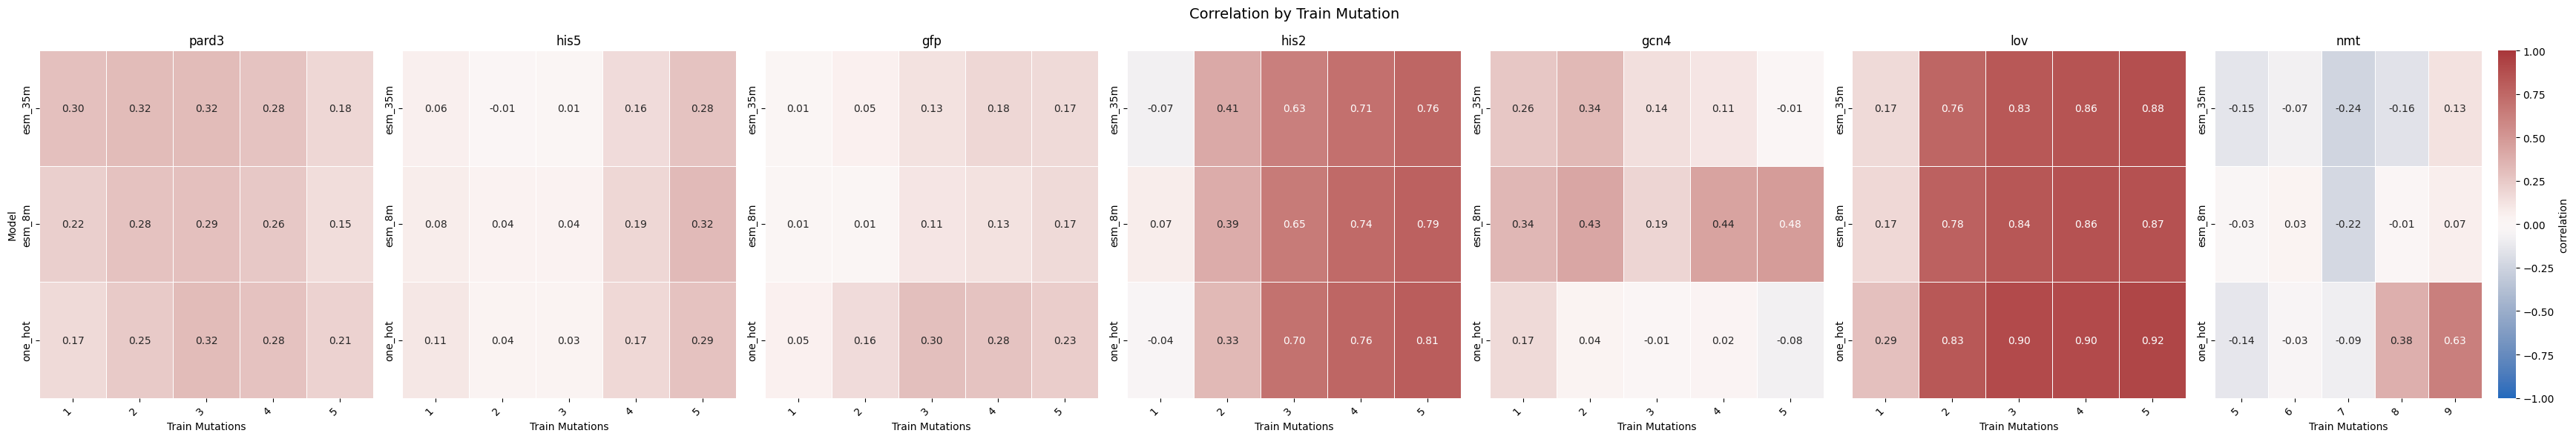

In [68]:
fig, ax = plot_mutation_heatmaps_by_dataset(
    final_df,
    mode="train",
    metric="correlation",
)